# Proyecto IA — Análisis exploratorio de datos

## Grupo 5

Este notebook presenta la exploración del conjunto de datos utilizado para predecir el riesgo de ictus. Su objetivo es describir los datos, revisar su calidad y documentar los patrones observados antes de la fase de modelado.



### Cómo ejecutar este notebook

1. Seleccionar el intérprete de Python del entorno .venv del proyecto.
2. Ejecutar las celdas en orden desde el principio.
3. Mantener abierto el repositorio completo como espacio de trabajo.

Las conclusiones se fundamentan en los análisis y resultados obtenidos en este proyecto.



## 0. Carga de librerías

In [ ]:
# --- LIBRARIES ---

# Numeric operations and data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import recall_score

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

print("Libraries loaded")




✅ Librerías cargadas


In [ ]:
from pathlib import Path



# El notebook puede ejecutarse desde la raíz del repositorio o desde notebooks/

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "stroke_enriched.csv"





## 1. Preparación dataset

In [ ]:
df = pd.read_csv(DATA_PATH, na_values=['N/A'])
df.head()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,...,age_group,comorbidity_count,age_x_hypertension,age_x_heart,age_x_glucose,is_elderly,is_child,glucose_high,obese,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,...,senior,1,0.0,67.0,153.22,1,0,1,1,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,...,senior,0,0.0,0.0,123.35,1,0,1,0,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,...,senior,1,0.0,80.0,84.74,1,0,0,1,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,...,adulto,0,0.0,0.0,83.90,0,0,1,1,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,...,senior,1,79.0,0.0,137.55,1,0,1,0,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  5110 non-null   int64  
 1   gender              5110 non-null   object 
 2   age                 5110 non-null   float64
 3   hypertension        5110 non-null   int64  
 4   heart_disease       5110 non-null   int64  
 5   ever_married        5110 non-null   object 
 6   work_type           5110 non-null   object 
 7   Residence_type      5110 non-null   object 
 8   avg_glucose_level   5110 non-null   float64
 9   bmi                 4909 non-null   float64
 10  smoking_status      5110 non-null   object 
 11  bmi_missing         5110 non-null   int64  
 12  glucose_category    5110 non-null   object 
 13  bmi_category        5110 non-null   object 
 14  age_group           5110 non-null   object 
 15  comorbidity_count   5110 non-null   int64  
 16  age_x_

In [4]:
df.describe().round(3)

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,bmi_missing,comorbidity_count,age_x_hypertension,age_x_heart,age_x_glucose,is_elderly,is_child,glucose_high,obese,stroke
count,5110.000,5110.000,5110.000,5110.000,5110.000,4909.000,5110.000,5110.000,5110.000,5110.000,5110.000,5110.000,5110.000,5110.000,5110.000,5110.000
mean,36517.829,43.227,0.097,0.054,106.148,28.893,0.039,0.151,6.066,3.683,48.322,0.269,0.168,0.192,0.376,0.049
std,21161.722,22.613,0.297,0.226,45.284,7.854,0.194,0.392,18.976,15.649,38.836,0.444,0.373,0.394,0.484,0.215
min,67.000,0.080,0.000,0.000,55.120,10.300,0.000,0.000,0.000,0.000,0.060,0.000,0.000,0.000,0.000,0.000
25%,17741.250,25.000,0.000,0.000,77.245,23.500,0.000,0.000,0.000,0.000,21.792,0.000,0.000,0.000,0.000,0.000
50%,36932.000,45.000,0.000,0.000,91.885,28.100,0.000,0.000,0.000,0.000,39.595,0.000,0.000,0.000,0.000,0.000
75%,54682.000,61.000,0.000,0.000,114.090,33.100,0.000,0.000,0.000,0.000,60.798,1.000,0.000,0.000,1.000,0.000
max,72940.000,82.000,1.000,1.000,271.740,97.600,1.000,2.000,82.000,82.000,207.700,1.000,1.000,1.000,1.000,1.000


In [5]:
df.shape

(5110, 24)

In [6]:
# Valores nulos
is_null = df.isna().any()
print("Columnas con NULOS:")
print(df.isna().sum()[df.isna().sum() > 0])

Columnas con NULOS:
bmi    201
dtype: int64


In [7]:
# Valores infinitos
is_inf = df.isin([np.inf, -np.inf]).any()
print("Columnas con INFINITOS:")
print(is_inf[is_inf])

Columnas con INFINITOS:
Series([], dtype: bool)


In [8]:
# Valores duplicados
print("Columnas con DUPLICADOS:")
print(df.duplicated().sum())

Columnas con DUPLICADOS:
0


In [9]:
# Revisar categorías para que no haya inconsistencias
for col in df.select_dtypes(include="object"):
    print(col)
    print(df[col].unique())
    print()

gender
['Male' 'Female']

ever_married
['Yes' 'No']

work_type
['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']

Residence_type
['Urban' 'Rural']

smoking_status
['formerly smoked' 'never smoked' 'smokes' 'Unknown']

glucose_category
['diabetes' 'prediabetes' 'normal']

bmi_category
['obesidad' 'desconocido' 'normal' 'sobrepeso' 'bajo_peso']

age_group
['senior' 'adulto' 'adulto_joven' 'menor']



In [10]:
# Valores target (stroke)
df['stroke'].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [11]:
# Eliminar columna "id" ya que no aporta información relevante
df = df.drop(columns="id")

In [12]:
# Comprobación de que la columna "id" se ha eliminado correctamente
print("Columnas:\n", df.columns)
print("\nShape:", df.shape)

Columnas:
 Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'bmi_missing', 'glucose_category', 'bmi_category',
       'age_group', 'comorbidity_count', 'age_x_hypertension', 'age_x_heart',
       'age_x_glucose', 'is_elderly', 'is_child', 'glucose_high', 'obese',
       'stroke'],
      dtype='object')

Shape: (5110, 23)


## 2. Análisis exploratorio de los datos (EDA)

### Porcentaje de pacientes con ictus

In [13]:
(df["stroke"].value_counts(normalize=True) * 100).round(3)

stroke
0    95.127
1     4.873
Name: proportion, dtype: float64

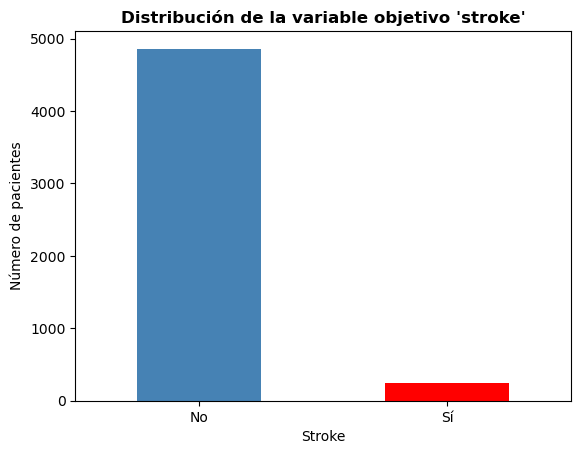

In [14]:
# Visualización del porcentaje
df["stroke"].value_counts().plot(kind="bar", color=["steelblue", "red"])

plt.title("Distribución de la variable objetivo 'stroke'", fontweight = "bold")
plt.xlabel("Stroke")
plt.ylabel("Número de pacientes")
plt.xticks([0,1],["No","Sí"], rotation=0)
plt.show()

In [15]:
# Cálculo de la accuracy si predecimos siempre "No hay ictus"
accuracy_no_ictus = (df["stroke"] == 0).mean()
print(f"Accuracy si un modelo siempre predijera 'No hay ictus': {accuracy_no_ictus:.2%}")

Accuracy si un modelo siempre predijera 'No hay ictus': 95.13%


In [16]:
# Predicción trivial: siempre "No hay ictus"
y_true = df["stroke"]
y_pred = [0] * len(df)

recall = recall_score(y_true, y_pred)
print(f"Recall si un modelo siempre predijera 'No hay ictus': {recall:.2f}")

Recall si un modelo siempre predijera 'No hay ictus': 0.00


> Un modelo que siempre predijera "No hay ictus" tendría un **95%** de **_accuracy_**, pero no detectaría nunca ningún ictus (`recall = 0`). Por ello, la accuracy no será una métrica adecuada y se priorizarán métricas como **Recall, F1-Score y ROC-AUC**.

### Valores faltantes en BMI

In [17]:
(df.groupby(df["bmi"].isna())["stroke"].mean() * 100).round(3)

bmi
False     4.257
True     19.900
Name: stroke, dtype: float64

> Observamos que los pacientes con **BMI conocido** presentan una tasa de ictus del **4%**, mientras que los pacientes con **BMI desconocido** presentan una tasa del **20%**. Esto indica que los pacientes del segundo grupo tienen una probabilidad casi **5 veces mayor**.
>
> Es por ello por lo que no podemos obviar esa información y sería conveniente rellenar esos datos con la mediana (es más robusta que la media).

### Fuerza variables categóricas

In [18]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(((df.groupby(col)["stroke"].mean().sort_values(ascending=False)) * 100).round(3), "\n")

gender
Male      5.106
Female    4.708
Name: stroke, dtype: float64 

ever_married
Yes    6.561
No     1.651
Name: stroke, dtype: float64 

work_type
Self-employed    7.937
Private          5.094
Govt_job         5.023
children         0.291
Never_worked     0.000
Name: stroke, dtype: float64 

Residence_type
Urban    5.200
Rural    4.535
Name: stroke, dtype: float64 

smoking_status
formerly smoked    7.910
smokes             5.323
never smoked       4.757
Unknown            3.044
Name: stroke, dtype: float64 

glucose_category
diabetes       10.194
prediabetes     3.707
normal          3.577
Name: stroke, dtype: float64 

bmi_category
desconocido    19.900
sobrepeso       5.323
obesidad        5.104
normal          2.816
bajo_peso       0.297
Name: stroke, dtype: float64 

age_group
senior          13.154
adulto           3.836
adulto_joven     0.457
menor            0.234
Name: stroke, dtype: float64 



> Las variables que muestran diferencias grandes son **ever_married, work_type y smoking_status**.

### Fuerza variables numéricas

In [19]:
numeric_columns = df.select_dtypes(include=["int64","float64"]).columns

for col in numeric_columns:
    print(((df.groupby(col)["stroke"].mean().sort_values(ascending=False)) * 100).round(3), "\n")

age
80.0    24.286
81.0    23.333
74.0    22.500
78.0    20.588
79.0    20.000
         ...  
11.0     0.000
10.0     0.000
9.0      0.000
8.0      0.000
31.0     0.000
Name: stroke, Length: 104, dtype: float64 

hypertension
1    13.253
0     3.968
Name: stroke, dtype: float64 

heart_disease
1    17.029
0     4.179
Name: stroke, dtype: float64 

avg_glucose_level
271.74    100.0
174.12    100.0
194.37    100.0
194.99    100.0
195.23    100.0
          ...  
83.89       0.0
83.91       0.0
83.93       0.0
83.94       0.0
95.19       0.0
Name: stroke, Length: 3979, dtype: float64 

bmi
44.1    100.0
36.5     75.0
42.5     50.0
45.7     50.0
56.6     50.0
        ...  
27.6      0.0
26.0      0.0
25.9      0.0
25.7      0.0
97.6      0.0
Name: stroke, Length: 418, dtype: float64 

bmi_missing
1    19.900
0     4.257
Name: stroke, dtype: float64 

comorbidity_count
2    20.312
1    13.467
0     3.386
Name: stroke, dtype: float64 

age_x_hypertension
68.0    40.000
80.0    33.333
74.0    

### Menores con ictus

In [20]:
# Calcular número de menores en el dataset
menores = df[df["age"] < 18]

print(f"Número de menores: {len(menores)}")
print(f"Porcentaje: {len(menores)/len(df)*100:.2f}%")

Número de menores: 856
Porcentaje: 16.75%


In [21]:
# Menores con ictus
menores["stroke"].value_counts()

print("Tasa de ictus en menores:", (menores["stroke"].mean()*100).round(2))

Tasa de ictus en menores: 0.23


In [22]:
# Influencia de otras variables sobre los menores
variables = [
    "work_type",
    "smoking_status",
    "ever_married",
    "gender",
    "Residence_type"
]

for variable in variables:

    print(f"\n{'='*50}")
    print(variable)

    tabla = pd.crosstab(
        df["age"] < 18,
        df[variable],
        normalize="index"
    ) * 100

    print(tabla.round(2))


work_type
work_type  Govt_job  Never_worked  Private  Self-employed  children
age                                                                
False          15.3          0.12    65.61          18.97      0.00
True            0.7          1.99    15.65           1.40     80.26

smoking_status
smoking_status  Unknown  formerly smoked  never smoked  smokes
age                                                           
False             20.26            20.22         41.18   18.34
True              79.67             2.92         16.36    1.05

ever_married
ever_married      No    Yes
age                        
False          21.18  78.82
True          100.00   0.00

gender
gender  Female   Male
age                  
False    60.58  39.42
True     48.83  51.17

Residence_type
Residence_type  Rural  Urban
age                         
False           49.01  50.99
True            50.12  49.88


> Las variables que más influyen sobre los menores son **work_type, smoking_status y ever_married** ya que eran las que mostraban más diferencias y están más influidas por la edad, el cual es uno de los principales factores de riesgo de ictus.

### Niveles de glucosa

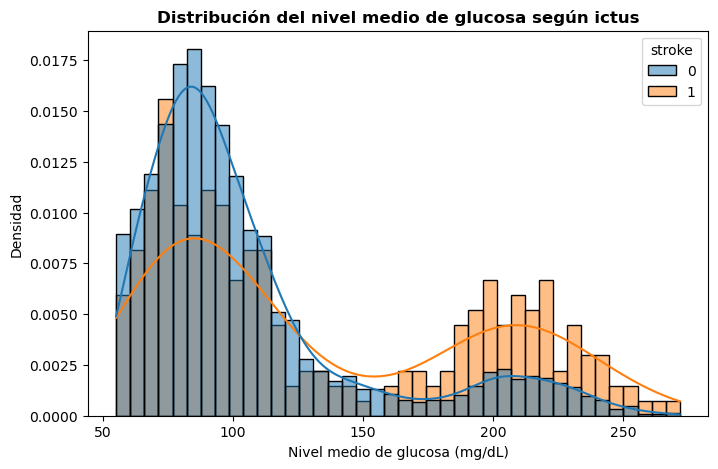

In [23]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="avg_glucose_level",
    hue="stroke",
    bins=40,
    kde=True,
    stat="density",
    common_norm=False
)

plt.title("Distribución del nivel medio de glucosa según ictus", fontweight = "bold")
plt.xlabel("Nivel medio de glucosa (mg/dL)")
plt.ylabel("Densidad")
plt.show()

> La distribución es **asimétrica** hacia la derecha (muestra una cola en valores elevados de glucosa) y puede sugerir la presencia de **más de una subpoblación**. Desde un punto de vista clínico podrían ser pacientes con **niveles de glucosa normales** (70 - 120 mg/dL) y pacientes con **hiperglucemia o diabetes** (150 - 250 mg/dL.)

### Matriz de correlación


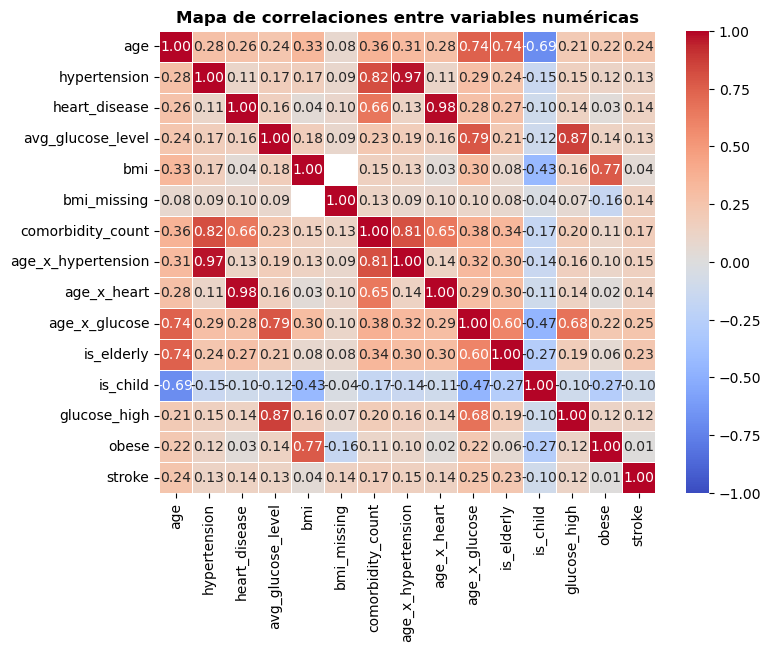

In [24]:
# Correlación variables numéricas
corr = df[numeric_columns].corr().round(3)

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Mapa de correlaciones entre variables numéricas", fontweight = "bold")
plt.show()

> Los pares con mayor correlación son las variables influenciadas por la **edad**, lo que demuestra que este es el factor de mayor riesgo ante un posible ictus. Cuanta más edad tenga el paciente, mayor probabilidad de padecer un ictus. Eso unido a factores como **la hipertensión, la enfermedad cardíaca, los niveles de glucosa y el BMI**, hacen que aumente dicha probabilidad.
>
> `bmi` y `bmi_missing` no muestran el tipo de correlación porque hay valores faltantes (NaN) en `bmi`.

## Conclusiones del análisis exploratorio

- La variable objetivo presenta un fuerte desequilibrio entre las clases, por lo que la evaluación posterior debe considerar métricas que describan específicamente la detección de ictus.
- El análisis revisa la información faltante de `bmi` y las relaciones observadas en variables demográficas, clínicas y de hábitos de vida.
- Las visualizaciones y tablas de esta fase sirven para justificar las decisiones de preprocesamiento y evaluación que se desarrollan en el segundo notebook.


